# Exploring the Impact of Linearity on Regression Fitted to Convex Hull Samples

In previous two hull tests, I first got some positive results, which are actually unintuitive. 
Then, I constructed a simple function Z = sin(sqrt(X^2+Y^2)) that can be fitted well by the full dataset but not the hullset. I suspected that the linearity impacts the performance of the hull a lot.

Author: Andrew Zhu

## Import Libraries

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

from scipy.spatial import ConvexHull
from sklearn.datasets import make_regression

# Print package versions for reproducibility
print('Versions of imported libraries:')
print(f"  matplotlib: {mpl.__version__}")
print(f"  numpy: {np.__version__}")
print(f"  pandas: {pd.__version__}")
print(f"  seaborn: {sns.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  xgboost: {xgboost.__version__}")

Versions of imported libraries:
  matplotlib: 3.11.2
  numpy: 2.5.4
  pandas: 3.0.6
  seaborn: 0.13.2
  scikit-learn: 1.9.1
  xgboost: 3.4.1


## Linear Regression & Extra Trees

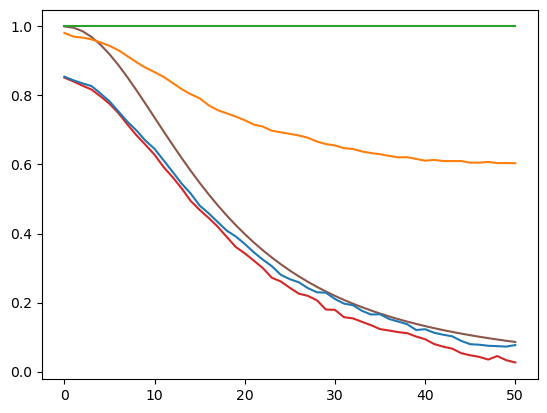

In [49]:
linearities = []
scores_full_train = []
scores_hull_train = []
scores_full_test = []
scores_hull_test = []
lr = LinearRegression()
et = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
for noise in range(0,510,10):
    X, y = make_regression(n_samples = 1000, n_features = 8, noise = noise, random_state = 42)
    lr.fit(X,y)
    linearities.append(lr.score(X,y))
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    scaler = StandardScaler()
    Xtrain = scaler.fit_transform(X_train)
    Xtest = scaler.transform(X_test)
    
    et.fit(X_train, y_train)
    scores_full_test.append(et.score(X_test, y_test))
    scores_full_train.append(et.score(X_train, y_train))
    
    hull = ConvexHull(X_train)
    X_hull = X_train[hull.vertices]
    y_hull = y_train[hull.vertices]
    
    et.fit(X_hull, y_hull)
    scores_hull_test.append(et.score(X_test, y_test))
    scores_hull_train.append(et.score(X_train, y_train))

plt.plot(linearities, 'tab:brown')
plt.plot(scores_full_train, 'tab:green')
plt.plot(scores_hull_train, 'tab:orange')
plt.plot(scores_full_test, 'tab:red')
plt.plot(scores_hull_test, 'tab:blue')
plt.show()

Observation: The Extra Trees failed to differentiate two datasets, let's try other models

## Neural Network

In [20]:
scaler = StandardScaler()
Xtrain = scaler.fit_transform(X_train)
Xtest = scaler.transform(X_test)

In [42]:
layers = (128,64)
model = MLPRegressor(hidden_layer_sizes=layers,random_state=42, max_iter=60000, alpha=0.01)
model.fit(X_train, y_train)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

0.9810215478372294
-1.048913014594973


In [45]:
layers = (128,64,32,16,8)
model.fit(X_hull, y_hull)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

0.1287663621575309
0.07333747284172043


## Training Set Performance

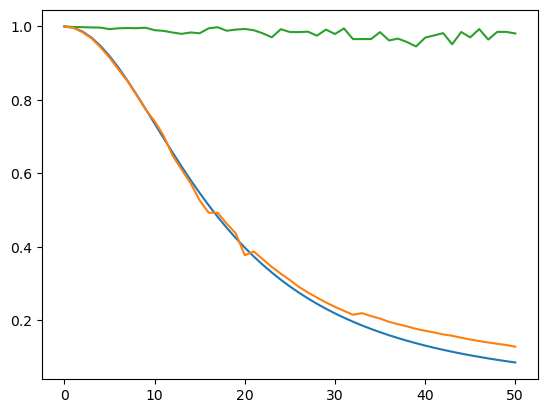

In [ ]:
# Since nn overfits, let's plot the performance on training set first
linearities = []
scores_full = []
scores_hull = []
lr = LinearRegression()
et = ExtraTreesRegressor(n_estimators = 100, random_state = 42)
for noise in range(0,510,10):
    X, y = make_regression(n_samples = 1000, n_features = 8, noise = noise, random_state = 42)
    lr.fit(X,y)
    linearities.append(lr.score(X,y))
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    scaler = StandardScaler()
    Xtrain = scaler.fit_transform(X_train)
    Xtest = scaler.transform(X_test)
    
    model.fit(X_train, y_train)
    scores_full.append(model.score(X_train, y_train))
    
    hull = ConvexHull(X_train)
    X_hull = X_train[hull.vertices]
    y_hull = y_train[hull.vertices]
    
    model.fit(X_hull, y_hull)
    scores_hull.append(model.score(X_train, y_train))
plt.plot(linearities, 'tab:blue')
plt.plot(scores_full, 'tab:green')
plt.plot(scores_hull, 'tab:orange')
plt.show()

Observation: At least the full dataset overfits